In [18]:
!pip install duckdb -q

import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import folium
from folium.plugins import FastMarkerCluster, HeatMap
from google.colab import files

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
from google.colab import files
uploaded = files.upload()

Saving citymotion_pune_realtime.csv to citymotion_pune_realtime (1).csv
Saving dashboard_corridor_scorecard.csv to dashboard_corridor_scorecard (1).csv
Saving dim_corridors.csv to dim_corridors (1).csv
Saving fact_incidents.csv to fact_incidents (1).csv


In [20]:
df_realtime = pd.read_csv("citymotion_pune_realtime.csv")
dim_corridors = pd.read_csv("dim_corridors.csv")
fact_incidents = pd.read_csv("fact_incidents.csv")
scorecard = pd.read_csv("dashboard_corridor_scorecard.csv")

df_realtime["active_incident"] = df_realtime["active_incident"].fillna("No Incident")
df_realtime["timestamp"] = pd.to_datetime(df_realtime["timestamp"])

dim_time = df_realtime[["timestamp", "day_type", "hour_of_day"]].drop_duplicates().copy()
dim_time["time_period"] = dim_time["hour_of_day"].apply(
    lambda h: "Morning Peak (08-11)" if 8 <= h <= 11
    else ("Evening Peak (17-21)" if 17 <= h <= 21
    else ("Night Free-Flow (00-05)" if 0 <= h <= 5 else "Off-Peak Daytime"))
)

con = duckdb.connect()
con.register("mobility", df_realtime)
con.register("corridors", dim_corridors)
con.register("incidents", fact_incidents)
con.register("time_dim", dim_time)

print("All 4 tables loaded, cleaned, and registered in SQL!")
print("Total Telemetry Rows:", len(df_realtime))

All 4 tables loaded, cleaned, and registered in SQL!
Total Telemetry Rows: 1200


In [21]:
print("=== 1. CITYWIDE BASELINE KPIs ===")
kpi_df = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT corridor_id) AS corridors_monitored,
        ROUND(AVG(actual_speed_kmph), 2) AS avg_speed_kmph,
        ROUND(AVG((free_flow_speed_kmph - actual_speed_kmph) / free_flow_speed_kmph) * 100, 2) AS avg_congestion_index_pct,
        ROUND(SUM(CASE WHEN bus_delay_mins <= 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 1) AS overall_transit_otp_pct
    FROM mobility
""").df()
display(kpi_df)

=== 1. CITYWIDE BASELINE KPIs ===


,total_records,corridors_monitored,avg_speed_kmph,avg_congestion_index_pct,overall_transit_otp_pct
0,1200,25,36.5,27.3,73.0


In [22]:
print("=== 2. TOP 10 MOST CONGESTED PUNE CORRIDORS ===")
top_congested = con.execute("""
    SELECT
        route_short_name,
        corridor_name,
        ROUND(AVG(actual_speed_kmph), 2) AS avg_speed_kmph,
        ROUND(AVG((free_flow_speed_kmph - actual_speed_kmph) / free_flow_speed_kmph) * 100, 2) AS congestion_index_pct,
        ROUND(AVG((road_length_km / actual_speed_kmph) * 60), 1) AS avg_travel_mins,
        ROUND(PERCENTILE_CONT(0.95) WITHIN GROUP (ORDER BY (road_length_km / actual_speed_kmph) * 60), 1) AS p95_travel_mins
    FROM mobility
    GROUP BY 1, 2
    ORDER BY congestion_index_pct DESC
    LIMIT 10
""").df()
display(top_congested)

=== 2. TOP 10 MOST CONGESTED PUNE CORRIDORS ===


,route_short_name,corridor_name,avg_speed_kmph,congestion_index_pct,avg_travel_mins,p95_travel_mins
0,99,Kekan Gas ⇆ Kothrud Depot,35.10,29.80,13.5,22.4
1,170,Yewalewadi ⇆ Pune Station Depot,31.85,29.22,22.8,40.6
2,167,Kesnand Phata Wagholi ⇆ Bhekrai Nagar,39.20,28.73,14.2,23.1
3,4,Shivaji Nagar ⇆ Swargate,35.65,28.70,22.2,39.4
4,5,Pune Station Moledina Stand ⇆ Swargate,39.36,28.43,18.0,31.3
5,357,Bhosari Terminal ⇆ Pune Station Sassoon Road,35.79,28.42,27.3,47.3
6,149,Nigdi Bhakti Shakti Stand ⇆ Hadapsar Gadital,35.81,28.38,31.0,50.7
7,98,Kesnand Phata Wagholi ⇆ Ganpati Matha,32.36,28.09,32.4,55.9
8,13,Shivaji Nagar ⇆ Upper Depot,36.26,27.48,13.7,24.6
9,361,Bhosari Pmt Chowk ⇆ Alandi,36.38,27.23,13.9,24.9


In [23]:
print("=== 3. WEEKDAY VS. WEEKEND COMPARISON ===")
day_type_df = con.execute("""
    SELECT
        day_type,
        ROUND(AVG(vehicle_count), 0) AS avg_hourly_vehicles,
        ROUND(AVG(actual_speed_kmph), 2) AS avg_speed_kmph,
        ROUND(AVG((free_flow_speed_kmph - actual_speed_kmph) / free_flow_speed_kmph) * 100, 2) AS congestion_index_pct,
        ROUND(AVG(bus_delay_mins), 2) AS avg_bus_delay_mins
    FROM mobility
    GROUP BY day_type
""").df()
display(day_type_df)

=== 3. WEEKDAY VS. WEEKEND COMPARISON ===


,day_type,avg_hourly_vehicles,avg_speed_kmph,congestion_index_pct,avg_bus_delay_mins
0,Weekday,377.0,34.96,30.38,5.02
1,Weekend,300.0,38.04,24.22,2.65


In [24]:
print("=== 4. INCIDENT IMPACT ANALYSIS ===")
incident_df = con.execute("""
    SELECT
        active_incident,
        COUNT(*) AS affected_hours,
        ROUND(AVG(actual_speed_kmph), 2) AS avg_speed_kmph,
        ROUND(AVG((free_flow_speed_kmph - actual_speed_kmph) / free_flow_speed_kmph) * 100, 2) AS congestion_index_pct,
        ROUND(AVG(bus_delay_mins), 1) AS avg_bus_delay_mins
    FROM mobility
    GROUP BY active_incident
    ORDER BY avg_speed_kmph ASC
""").df()
display(incident_df)

=== 4. INCIDENT IMPACT ANALYSIS ===


,active_incident,affected_hours,avg_speed_kmph,congestion_index_pct,avg_bus_delay_mins
0,Signal Failure,9,17.26,65.21,14.7
1,Roadwork,7,18.34,63.33,14.7
2,Accident,4,22.46,54.71,9.8
3,Waterlogging,3,25.94,50.24,9.0
4,No Incident,1177,36.83,26.64,3.7


In [25]:
load_pct = df_realtime["passenger_load"] * 100 / df_realtime["bus_capacity"]
print("Passenger load % distribution (all rows):")
print(load_pct.describe().round(1))

LOAD_THRESHOLD = 65
OTP_THRESHOLD = 75

print("\n=== 5. PUBLIC TRANSIT RELIABILITY & OPTIMIZATION (all corridors) ===")
transit_reco = con.execute(f"""
    SELECT
        route_short_name,
        corridor_name,
        ROUND(SUM(CASE WHEN bus_delay_mins <= 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 1) AS otp_pct,
        ROUND(AVG(bus_delay_mins), 1) AS avg_delay_mins,
        ROUND(AVG(passenger_load * 100.0 / bus_capacity), 1) AS avg_load_pct,
        CASE
            WHEN AVG(passenger_load * 100.0 / bus_capacity) >= {LOAD_THRESHOLD}
                 AND (SUM(CASE WHEN bus_delay_mins <= 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) < {OTP_THRESHOLD}
            THEN 'CRITICAL: Add Express Buses & Bus Lane'
            ELSE 'MONITOR: Optimize Peak Headway'
        END AS recommendation
    FROM mobility
    GROUP BY 1, 2
    ORDER BY
        CASE WHEN AVG(passenger_load * 100.0 / bus_capacity) >= {LOAD_THRESHOLD}
                  AND (SUM(CASE WHEN bus_delay_mins <= 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) < {OTP_THRESHOLD}
             THEN 0 ELSE 1 END,
        avg_load_pct DESC
""").df()

display(transit_reco)
print("Recommendation counts:")
print(transit_reco["recommendation"].value_counts())

Passenger load % distribution (all rows):
count    1200.0
mean       64.5
std        31.1
min        14.0
25%        39.5
50%        64.0
75%        86.0
max       130.0
dtype: float64

=== 5. PUBLIC TRANSIT RELIABILITY & OPTIMIZATION (all corridors) ===


,route_short_name,corridor_name,otp_pct,avg_delay_mins,avg_load_pct,recommendation
0,149,Nigdi Bhakti Shakti Stand ⇆ Hadapsar Gadital,66.7,4.3,65.9,CRITICAL: Add Express Buses & Bus Lane
1,170,Yewalewadi ⇆ Pune Station Depot,70.8,4.0,65.6,CRITICAL: Add Express Buses & Bus Lane
2,42,Nigdi Bhakti Shakti ⇆ Gujarwadi Pmt Bus Stand,70.8,3.9,65.5,CRITICAL: Add Express Buses & Bus Lane
3,357,Bhosari Terminal ⇆ Pune Station Sassoon Road,70.8,4.4,65.3,CRITICAL: Add Express Buses & Bus Lane
4,291,Hadapsar Gadital ⇆ Katraj Kondhwa Road,64.6,4.6,65.2,CRITICAL: Add Express Buses & Bus Lane
5,304,Bhosari Gavhane Vasti ⇆ Chinchwadgaon,72.9,4.0,65.1,CRITICAL: Add Express Buses & Bus Lane
6,189,Dhangar Vasti ⇆ Hadapsar Gadital,79.2,3.5,66.7,MONITOR: Optimize Peak Headway
7,301,Shewalewadi Depot ⇆ Katraj,77.1,3.1,66.2,MONITOR: Optimize Peak Headway
8,5,Pune Station Moledina Stand ⇆ Swargate,75.0,3.7,65.4,MONITOR: Optimize Peak Headway
9,114,Bajirao Padale Chowk Mhalunge ⇆ Ma Na Pa Main ...,81.3,3.3,65.1,MONITOR: Optimize Peak Headway


Recommendation counts:
recommendation
MONITOR: Optimize Peak Headway            19
CRITICAL: Add Express Buses & Bus Lane     6
Name: count, dtype: int64


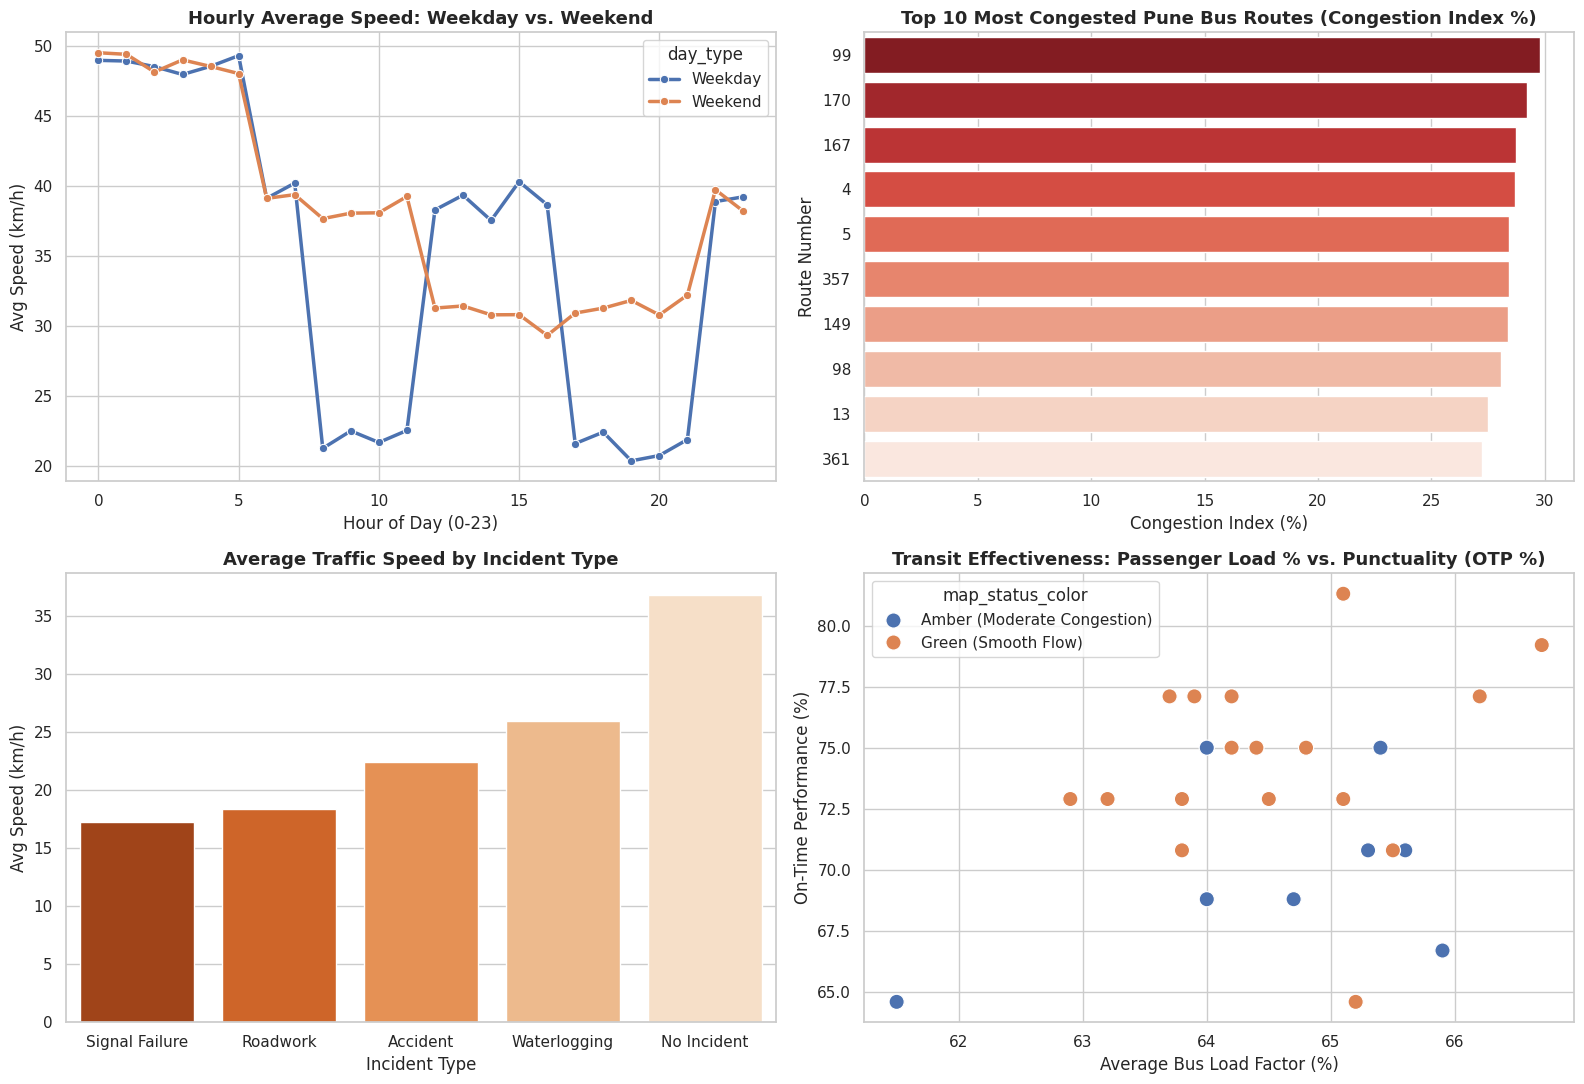

In [26]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1) Hourly speed: weekday vs weekend
hourly_df = df_realtime.groupby(["hour_of_day", "day_type"])["actual_speed_kmph"].mean().reset_index()
sns.lineplot(data=hourly_df, x="hour_of_day", y="actual_speed_kmph", hue="day_type",
             marker="o", linewidth=2.5, ax=axes[0, 0])
axes[0, 0].set_title("Hourly Average Speed: Weekday vs. Weekend", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day (0-23)")
axes[0, 0].set_ylabel("Avg Speed (km/h)")

# 2) Top 10 congested routes
top10_corr = scorecard.sort_values("congestion_index_pct", ascending=False).head(10).copy()
top10_corr["route_short_name"] = top10_corr["route_short_name"].astype(str)
sns.barplot(data=top10_corr, x="congestion_index_pct", y="route_short_name",
            hue="route_short_name", palette="Reds_r", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Most Congested Pune Bus Routes (Congestion Index %)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Congestion Index (%)")
axes[0, 1].set_ylabel("Route Number")

# 3) Speed by incident type
inc_df = df_realtime.groupby("active_incident")["actual_speed_kmph"].mean().sort_values().reset_index()
sns.barplot(data=inc_df, x="active_incident", y="actual_speed_kmph",
            hue="active_incident", palette="Oranges_r", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Average Traffic Speed by Incident Type", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Incident Type")
axes[1, 0].set_ylabel("Avg Speed (km/h)")

# 4) Load vs OTP
sns.scatterplot(data=scorecard, x="bus_load_pct", y="transit_otp_pct",
                hue="map_status_color", s=120, ax=axes[1, 1])
axes[1, 1].set_title("Transit Effectiveness: Passenger Load % vs. Punctuality (OTP %)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Average Bus Load Factor (%)")
axes[1, 1].set_ylabel("On-Time Performance (%)")

plt.tight_layout()
plt.savefig("citymotion_analysis_charts.png", dpi=300)
plt.show()

In [27]:
hourly_df = df_realtime.groupby(["hour_of_day", "day_type"])["actual_speed_kmph"].mean().reset_index()
sns.lineplot(data=hourly_df, x="hour_of_day", y="actual_speed_kmph", hue="day_type", marker="o", linewidth=2.5, ax=axes[0, 0])
axes[0, 0].set_title("Hourly Average Speed: Weekday vs. Weekend", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day (0-23)")
axes[0, 0].set_ylabel("Avg Speed (km/h)")

Text(28.0, 0.5, 'Avg Speed (km/h)')

In [28]:
top10_corr = scorecard.sort_values("congestion_index_pct", ascending=False).head(10)
sns.barplot(data=top10_corr, x="congestion_index_pct", y="route_short_name", palette="Reds_r", ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Most Congested Pune Bus Routes (Congestion Index %)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Congestion Index (%)")
axes[0, 1].set_ylabel("Route Number")

/tmp/ipykernel_587/709658348.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_corr, x="congestion_index_pct", y="route_short_name", palette="Reds_r", ax=axes[0, 1])


Text(816.4999999999999, 0.5, 'Route Number')

In [29]:
inc_df = df_realtime.groupby("active_incident")["actual_speed_kmph"].mean().sort_values().reset_index()
sns.barplot(data=inc_df, x="active_incident", y="actual_speed_kmph", palette="Oranges_r", ax=axes[1, 0])
axes[1, 0].set_title("Average Traffic Speed by Incident Type", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Incident Type")
axes[1, 0].set_ylabel("Avg Speed (km/h)")

/tmp/ipykernel_587/1691127708.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=inc_df, x="active_incident", y="actual_speed_kmph", palette="Oranges_r", ax=axes[1, 0])


Text(28.0, 0.5, 'Avg Speed (km/h)')

In [30]:
sns.scatterplot(data=scorecard, x="bus_load_pct", y="transit_otp_pct", hue="map_status_color", s=120, ax=axes[1, 1])
axes[1, 1].set_title("Transit Effectiveness: Passenger Load % vs. Punctuality (OTP %)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Average Bus Load Factor (%)")
axes[1, 1].set_ylabel("On-Time Performance (%)")

plt.tight_layout()
plt.savefig("citymotion_analysis_charts.png", dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

In [31]:
m = folium.Map(location=[18.5204, 73.8567], zoom_start=11, tiles="OpenStreetMap")
color_map = {
    "Red (Severe Congestion)": "red",
    "Amber (Moderate Congestion)": "orange",
    "Green (Smooth Flow)": "green"
}

for _, row in scorecard.iterrows():
    popup_text = (
        f"<b>Route {row['route_short_name']}:</b> {row['corridor_name']}<br>"
        f"<b>Avg Speed:</b> {row['avg_speed_kmph']} km/h<br>"
        f"<b>Congestion Index:</b> {row['congestion_index_pct']}%<br>"
        f"<b>Transit OTP:</b> {row['transit_otp_pct']}%<br>"
        f"<b>Bus Load:</b> {row['bus_load_pct']}%"
    )
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=10,
        color=color_map.get(row["map_status_color"], "blue"),
        fill=True,
        fill_opacity=0.8,
        popup=folium.Popup(popup_text, max_width=260),
        tooltip=f"Route {row['route_short_name']} ({row['congestion_index_pct']}% Congestion)"
    ).add_to(m)

m.save("pune_citymotion_dashboard_map.html")
print("Saved 'citymotion_analysis_charts.png' and 'pune_citymotion_dashboard_map.html'!")
m

Saved 'citymotion_analysis_charts.png' and 'pune_citymotion_dashboard_map.html'!


In [32]:
import shutil, os

os.makedirs("powerbi_data", exist_ok=True)

df_realtime.to_csv("powerbi_data/fact_mobility_clean.csv", index=False)
dim_time.to_csv("powerbi_data/dim_time.csv", index=False)
transit_reco.to_csv("powerbi_data/transit_recommendations.csv", index=False)
dim_corridors.to_csv("powerbi_data/dim_corridors.csv", index=False)
fact_incidents.to_csv("powerbi_data/fact_incidents.csv", index=False)
scorecard.to_csv("powerbi_data/dashboard_corridor_scorecard.csv", index=False)

shutil.copy("citymotion_analysis_charts.png", "powerbi_data/")
shutil.copy("pune_citymotion_dashboard_map.html", "powerbi_data/")

shutil.make_archive("powerbi_data", "zip", "powerbi_data")
print("Created powerbi_data.zip with:", os.listdir("powerbi_data"))
files.download("powerbi_data.zip")

Created powerbi_data.zip with: ['dim_time.csv', 'dashboard_corridor_scorecard.csv', 'pune_citymotion_dashboard_map.html', 'transit_recommendations.csv', 'fact_incidents.csv', 'fact_mobility_clean.csv', 'dim_corridors.csv', 'citymotion_analysis_charts.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>